## Лабораторная работа №1 | Вариант 5

Выполнил: 

### 1. Numpy

In [61]:
import numpy as np

1. Создайте единичную матрицу размером 3х3

In [62]:
matrix = np.eye(3)
print(matrix)

[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


2. Создайте кастомный dtype который описывает цвет состоящий из 4х unsigned bytes(RGBA пиксель)

In [63]:
rgba = np.dtype([
    ('R', np.uint8),
    ('G', np.uint8),
    ('B', np.uint8),
    ('A', np.uint8)
])
pixel = np.array((255, 128, 64, 255), dtype=rgba)

print(pixel)

(255, 128, 64, 255)


3. Как игнорировать все numpy warnings(не рекомендуем к использованию)?

In [64]:
old_settings = np.seterr(all='ignore')
print('Предупреждения о вычислительных ошибках NumPy отключены')

Предупреждения о вычислительных ошибках NumPy отключены


4. Создайте случайный вектор размера 10 и отсортируйте его

In [65]:
vect = np.random.random(10)
vect.sort()
print(vect)

[0.05788926 0.087037   0.30669439 0.45205094 0.50276408 0.62760513
 0.63187195 0.63907666 0.86989686 0.9275329 ]


5. Создайте read-only массив(неизменяемый)

In [66]:
arr = np.arange(10)
arr.setflags(write=False)
print(arr)

[0 1 2 3 4 5 6 7 8 9]


6. Рассмотрим случайную матрицу размером 10х2, представляющую декартовы координаты, преобразуем их в полярные координаты

In [67]:
points = np.random.random((10, 2))
x = points[:, 0]
y = points[:, 1]

r = np.sqrt(x ** 2 + y ** 2)
phi = np.arctan2(y, x)
polar = np.column_stack((r, phi))
print('Полярные координаты (радиус, угол):')
print(polar)

Полярные координаты (радиус, угол):
[[1.04402709 0.74370118]
 [0.83341396 1.52258355]
 [0.82833429 1.23071384]
 [0.17566127 0.55822044]
 [0.64870689 0.72961906]
 [0.38306617 0.12750504]
 [0.74424246 1.22699043]
 [0.26096683 1.15708063]
 [0.32810486 1.35424053]
 [0.79950627 0.52499346]]


7. Создайте структурированный массив с координатами x и y, охватывающий область [0,1]x[0,1]

In [68]:
coordinates = np.linspace(0, 1, 5)
grid = np.zeros((5, 5), dtype=[('x', float), ('y', float)])
grid['x'], grid['y'] = np.meshgrid(coordinates, coordinates)
print(grid)

[[(0.  , 0.  ) (0.25, 0.  ) (0.5 , 0.  ) (0.75, 0.  ) (1.  , 0.  )]
 [(0.  , 0.25) (0.25, 0.25) (0.5 , 0.25) (0.75, 0.25) (1.  , 0.25)]
 [(0.  , 0.5 ) (0.25, 0.5 ) (0.5 , 0.5 ) (0.75, 0.5 ) (1.  , 0.5 )]
 [(0.  , 0.75) (0.25, 0.75) (0.5 , 0.75) (0.75, 0.75) (1.  , 0.75)]
 [(0.  , 1.  ) (0.25, 1.  ) (0.5 , 1.  ) (0.75, 1.  ) (1.  , 1.  )]]


8. Учитывая два массива X и Y, постройте матрицу Коши $C$ ($C_{ij} =\frac{1}{x_i - y_j}$)

In [69]:
x = np.random.normal(size=5)
y = np.random.normal(size=5)


C = 1 / (x[:, np.newaxis] - y)
print(C)

[[  1.47350372   1.52270623  -1.91739259   0.98728063   7.28713178]
 [ -2.36529114  -2.24865647  -0.61615164 -11.29276841  -1.03712139]
 [  1.89522487   1.97740687  -1.48686884   1.16026703 -72.54539836]
 [  5.2791785    5.97035049  -0.98934208   1.90966483  -2.84088541]
 [  0.37834226   0.38150751   0.69304234   0.33587048   0.47580913]]


9. Как конвертировать массив float(32 bit) к массиву целых чисел (integer 32 bit) in place?

In [70]:
arr = np.array([1.2, 2.8, -3.7, 4.0], dtype=np.float32)
print('До:', arr, arr.dtype)



arr.view(np.int32)[:] = arr.astype(np.int32)
arr = arr.view(np.int32)
print('После:', arr, arr.dtype)

До: [ 1.2  2.8 -3.7  4. ] float32
После: [ 1  2 -3  4] int32


10. Как случайно заменить p элементов в 2D массиве?

In [71]:
arr = np.arange(1, 21).reshape(4, 5)
p = 5
print('До:\n', arr)


indices = np.random.choice(arr.size, size=p, replace=False)
arr.flat[indices] = 0
print('После:\n', arr)

До:
 [[ 1  2  3  4  5]
 [ 6  7  8  9 10]
 [11 12 13 14 15]
 [16 17 18 19 20]]
После:
 [[ 1  0  3  0  5]
 [ 0  7  8  9 10]
 [11 12 13 14  0]
 [16 17  0 19 20]]


### 2. Pandas

Найдите ответы на вопросы или выполните действия с предложенным датасетом 

Классический начальный набор данных - данные пассажиров титаника.

Файл: `data.csv`

```
PassangerId - уникальный номер пассажира
Survived - выжил человек или нет
Pclass - класс обслуживания
Name - имя человека, обращение к ней/нему
Sex - пол человека
Age - возраст на момент крушения
SibSp - количество братьев и сестер / супругов на борту "Титаника"
Parch - количество родителей / детей на борту "Титаника"
Ticket - номер билета
Fare - стоимость проезда для пассажиров
Cabin - каюта
Embarked - причал отбытия. C = Cherbourg Q = Queenstown S = Southampton
```

In [72]:
import pandas as pd

In [73]:
df = pd.read_csv('data.csv')
display(df.head())
print('Пропусков в возрасте:', df['Age'].isna().sum())


known_age = df.dropna(subset=['Age'])

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Пропусков в возрасте: 177


В заданиях ниже «дети до 16 лет» означает возраст строго меньше 16. Пассажиры с неизвестным возрастом исключены только из сравнений, где нужен возраст.

1. Узнайте сколько было на борту человек

In [74]:
print('Пассажиров в датасете:', len(df))

Пассажиров в датасете: 891


2. Какой медианный и средний возраста пассажиров

In [75]:
print('Медианный возраст:', df['Age'].median())
print('Средний возраст:', round(df['Age'].mean(), 2))

Медианный возраст: 28.0
Средний возраст: 29.7


3. Посчитайте процент выживаемости детей(до 16 лет) и взрослых

In [76]:
children = known_age[known_age['Age'] < 16]
adults = known_age[known_age['Age'] >= 16]
print('Выживаемость детей: {:.2f}%'.format(children['Survived'].mean() * 100))
print('Выживаемость взрослых: {:.2f}%'.format(adults['Survived'].mean() * 100))

Выживаемость детей: 59.04%
Выживаемость взрослых: 38.19%


4. Верна ли гипотеза, что женщины и дети сажались в шлюпки первыми и выживали больше?

In [77]:
groups = pd.Series({
    'Женщины': adults[adults['Sex'] == 'female']['Survived'].mean() * 100,
    'Мужчины': adults[adults['Sex'] == 'male']['Survived'].mean() * 100,
    'Дети до 16 лет': children['Survived'].mean() * 100
})
display(groups.round(2).rename('Выживаемость, %'))

Женщины           77.52
Мужчины           17.43
Дети до 16 лет    59.04
Name: Выживаемость, %, dtype: float64

Да, женщины и дети выживали чаще взрослых мужчин. Но порядок посадки в шлюпки по этим данным определить нельзя.

5. Зависит ли выживаемость от класса обслуживания?

In [78]:
class_survival = df.groupby('Pclass')['Survived'].mean() * 100
display(class_survival.round(2).rename('Выживаемость, %'))

Pclass
1    62.96
2    47.28
3    24.24
Name: Выживаемость, %, dtype: float64

Да, зависит: в первом классе выжили 63%, во втором - 47,3%, в третьем - 24,2%.

6. Посчитайте средний возраст умерших женщин и мужчин

In [79]:
dead = df[df['Survived'] == 0]
display(dead.groupby('Sex')['Age'].mean().round(2).rename('Средний возраст погибших'))

Sex
female    25.05
male      31.62
Name: Средний возраст погибших, dtype: float64

7. Различается ли процент выживаемости пассажиров с хотя бы одним родственником на борту и одиночек?

In [80]:
has_family = (df['SibSp'] + df['Parch']) > 0
print('С родственниками: {:.2f}%'.format(df.loc[has_family, 'Survived'].mean() * 100))
print('Одиночки: {:.2f}%'.format(df.loc[~has_family, 'Survived'].mean() * 100))

С родственниками: 50.56%
Одиночки: 30.35%


Да, с родственниками выживали чаще: 50,6% против 30,4% у одиночек.

8. Различается ли средняя стоимость билета у умерших и выживших пассажиров?

In [81]:
fare_by_survival = df.groupby('Survived')['Fare'].mean()
fare_by_survival.index = ['Погибшие', 'Выжившие']
display(fare_by_survival.round(2).rename('Средняя стоимость билета'))

Погибшие    22.12
Выжившие    48.40
Name: Средняя стоимость билета, dtype: float64

Да, у выживших средняя стоимость билета выше: 48,4 против 22,1 у погибших.

9. Выведите максимальный и минимальный возраст выживших пассажиров во 2 классе обслуживания

In [82]:
second_class_survivors = df[(df['Pclass'] == 2) & (df['Survived'] == 1)]
print('Минимальный возраст:', second_class_survivors['Age'].min())
print('Максимальный возраст:', second_class_survivors['Age'].max())

Минимальный возраст: 0.67
Максимальный возраст: 62.0


10. Подтвердите или опровергните гипотезу: молодым мужчинам(от 18 лет) выжить легче, чем более взрослым

In [83]:
men = known_age[(known_age['Sex'] == 'male') & (known_age['Age'] >= 18)]
young_men = men[men['Age'] <= 30]
older_men = men[men['Age'] > 30]
print('Мужчины 18–30 лет: {:.2f}% ({} человек)'.format(
    young_men['Survived'].mean() * 100, len(young_men)))
print('Мужчины старше 30 лет: {:.2f}% ({} человек)'.format(
    older_men['Survived'].mean() * 100, len(older_men)))

Мужчины 18–30 лет: 15.03% (193 человек)
Мужчины старше 30 лет: 20.30% (202 человек)


Нет, гипотеза не подтвердилась. Если считать молодыми мужчин 18 - 30 лет, среди них выжили 15%, а среди мужчин старше 30 лет - 20,3%.

### 3. Визуализация

Используя библиотеки matplotlib/sns/plotly/pandas и набор данных представленный ранее визуализируйте

1. Постройте гистограмму распределения возростов пассажиров

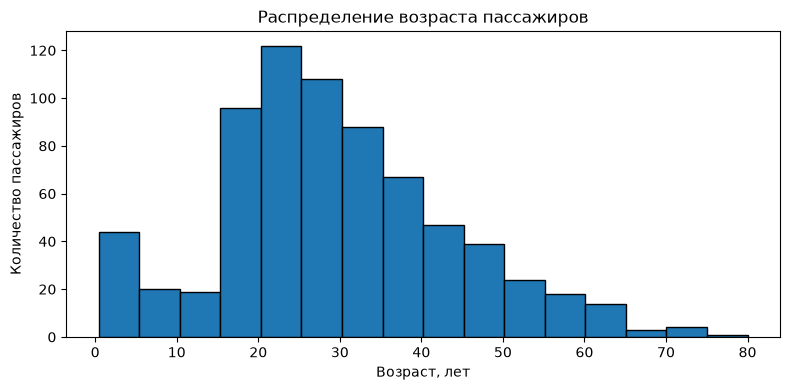

In [84]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.hist(df['Age'].dropna(), bins=16, edgecolor='black')
plt.title('Распределение возраста пассажиров')
plt.xlabel('Возраст, лет')
plt.ylabel('Количество пассажиров')
plt.tight_layout()
plt.show()

2. Постройте гистограммы распределения цен для пассажиров разных классов

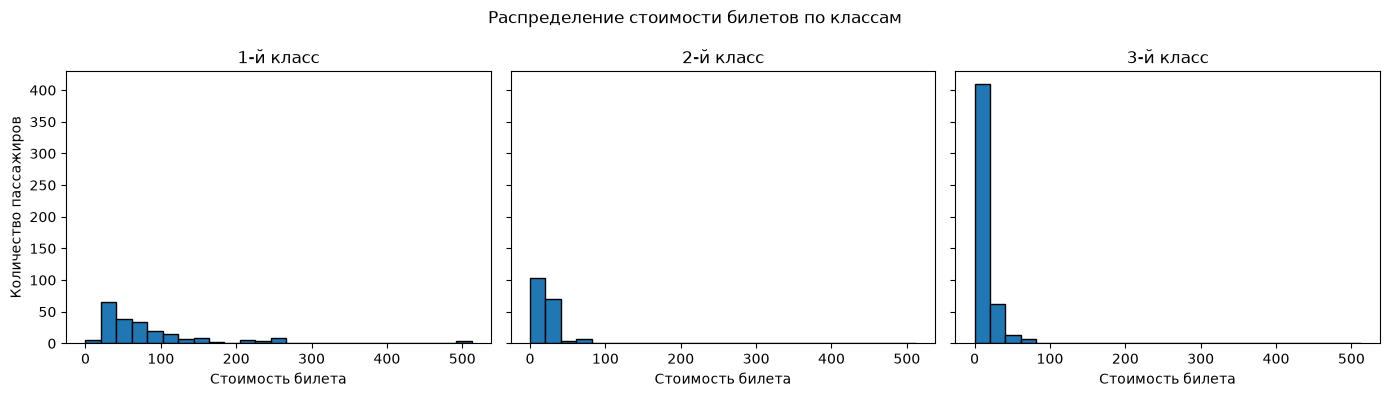

In [85]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True, sharey=True)
bins = np.linspace(0, df['Fare'].max(), 26)
for pclass, ax in zip([1, 2, 3], axes):
    ax.hist(df.loc[df['Pclass'] == pclass, 'Fare'].dropna(),
            bins=bins, edgecolor='black')
    ax.set_title(f'{pclass}-й класс')
    ax.set_xlabel('Стоимость билета')
axes[0].set_ylabel('Количество пассажиров')
fig.suptitle('Распределение стоимости билетов по классам')
plt.tight_layout()
plt.show()

3. Постройте зависимость цены от возраста пассажира

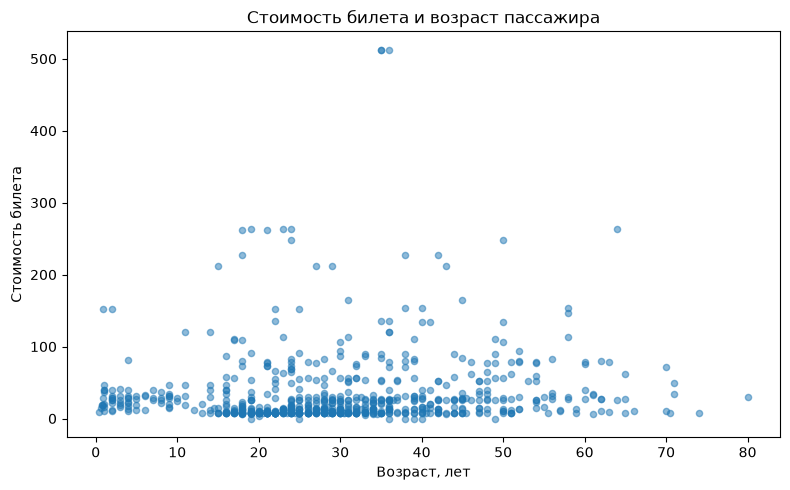

In [86]:
plt.figure(figsize=(8, 5))
plt.scatter(df['Age'], df['Fare'], alpha=0.5, s=20)
plt.title('Стоимость билета и возраст пассажира')
plt.xlabel('Возраст, лет')
plt.ylabel('Стоимость билета')
plt.tight_layout()
plt.show()

4. Постройте box plot отображающий распределение цен на билеты в разных классах

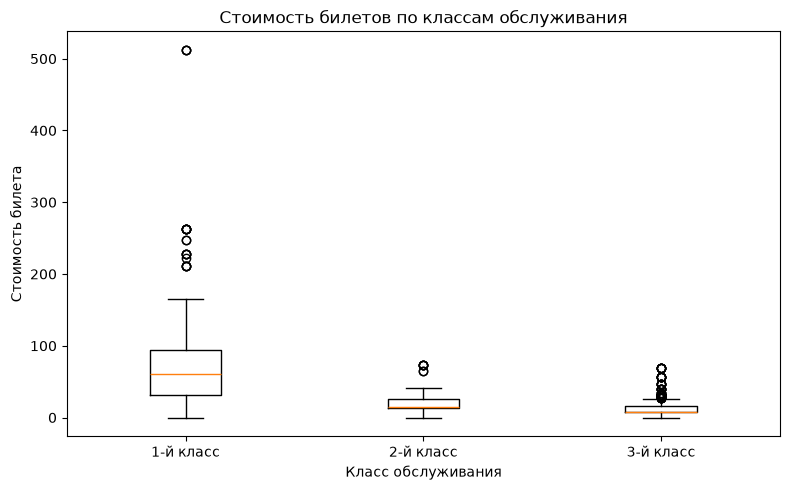

In [87]:
plt.figure(figsize=(8, 5))
fares = [df.loc[df['Pclass'] == pclass, 'Fare'].dropna() for pclass in [1, 2, 3]]
plt.boxplot(fares)
plt.xticks([1, 2, 3], ['1-й класс', '2-й класс', '3-й класс'])
plt.title('Стоимость билетов по классам обслуживания')
plt.xlabel('Класс обслуживания')
plt.ylabel('Стоимость билета')
plt.tight_layout()
plt.show()

5. Визуализируйте распределение долей выживших среди мужчин, женщин и детей(до 16 лет)

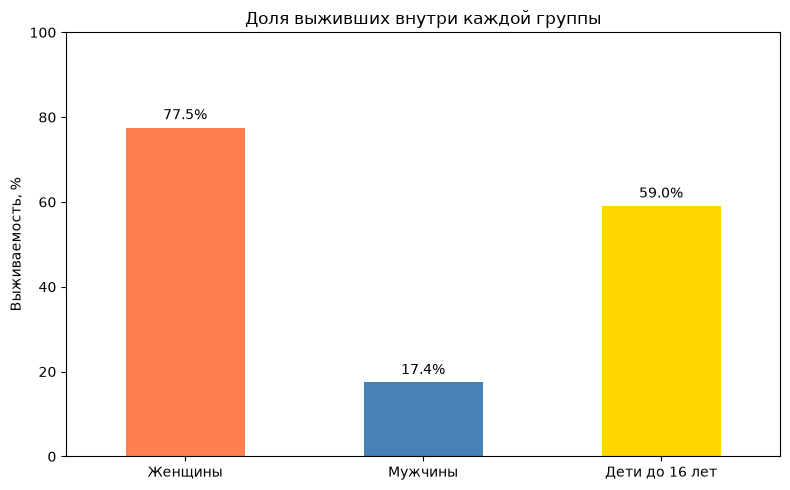

In [88]:
ax = groups.plot.bar(figsize=(8, 5), color=['coral', 'steelblue', 'gold'], rot=0)
ax.set_title('Доля выживших внутри каждой группы')
ax.set_ylabel('Выживаемость, %')
ax.set_ylim(0, 100)
for i, value in enumerate(groups):
    ax.text(i, value + 2, f'{value:.1f}%', ha='center')
plt.tight_layout()
plt.show()

6. Сравните плотности распределения возростов выживших и умерших пассажиров, сделайте выводы

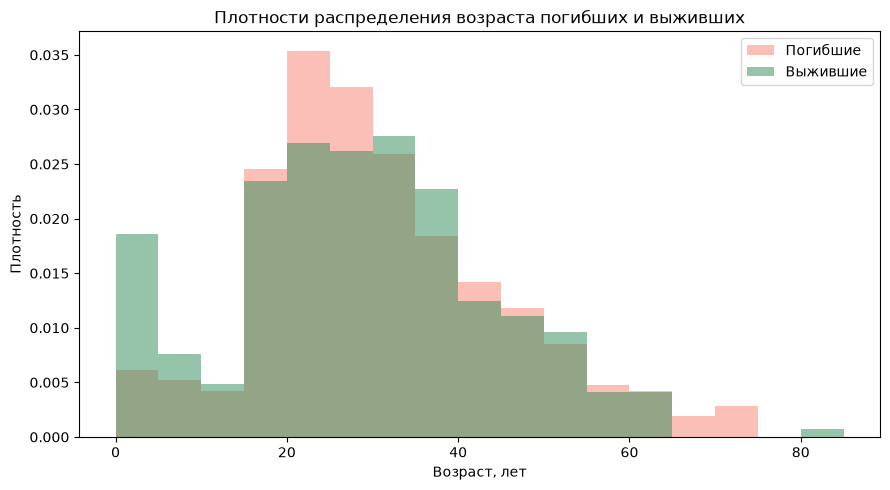

In [89]:
bins = np.arange(0, 86, 5)
plt.figure(figsize=(9, 5))
for survived, label, color in [(0, 'Погибшие', 'salmon'), (1, 'Выжившие', 'seagreen')]:
    ages = df.loc[df['Survived'] == survived, 'Age'].dropna()
    plt.hist(ages, bins=bins, density=True, alpha=0.5, label=label, color=color)
plt.title('Плотности распределения возраста погибших и выживших')
plt.xlabel('Возраст, лет')
plt.ylabel('Плотность')
plt.legend()
plt.tight_layout()
plt.show()

Среди выживших доля маленьких детей выше. В обеих группах много пассажиров в возрасте 20–40 лет.

7. Постройте круговую диаграмму отображающую выживаемость мужчин и женщин в разных классах обслуживания(визуализация должна быть интуитивно понятная без объяснений, женщины и мужчины соответствующих классов объеденены визуально в одну группу и 2 подгруппы)*

\* Задание на доп. балл

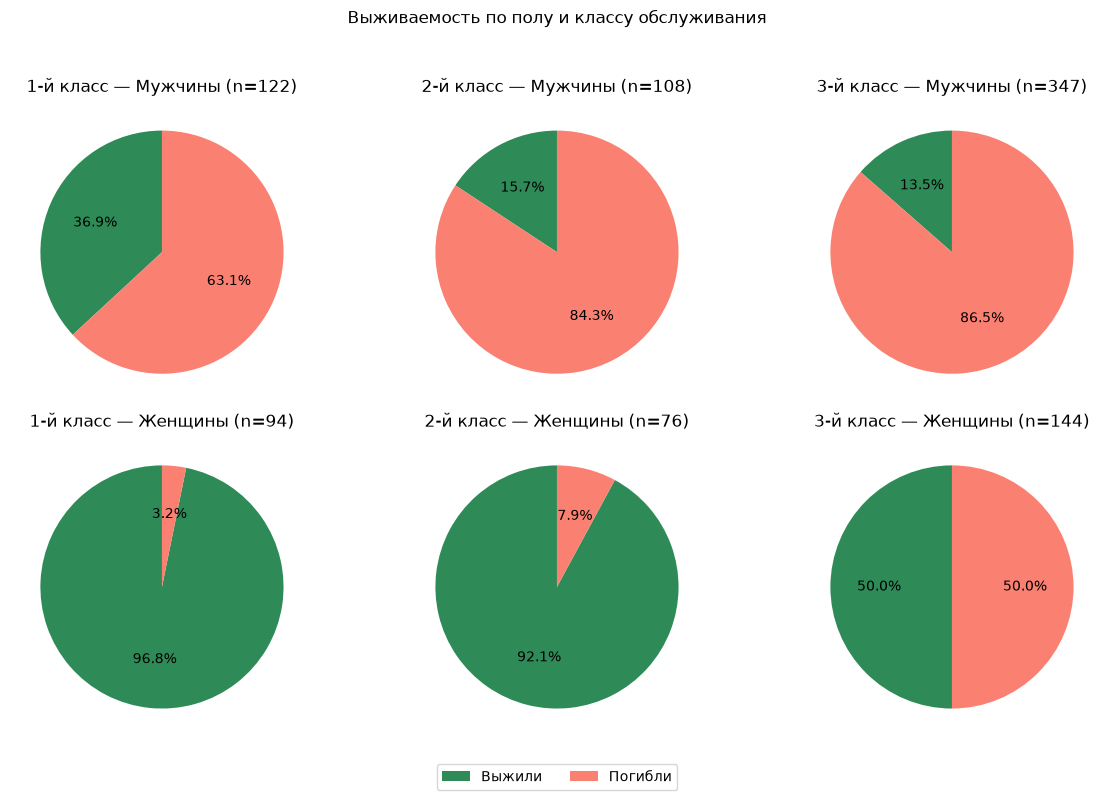

In [90]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for col, pclass in enumerate([1, 2, 3]):
    for row, (sex, label) in enumerate([('male', 'Мужчины'), ('female', 'Женщины')]):
        passengers = df[(df['Pclass'] == pclass) & (df['Sex'] == sex)]
        counts = passengers['Survived'].value_counts().reindex([1, 0], fill_value=0)
        axes[row, col].pie(counts, colors=['seagreen', 'salmon'], autopct='%1.1f%%',
                           startangle=90, textprops={'fontsize': 10})
        axes[row, col].set_title(f'{pclass}-й класс — {label} (n={len(passengers)})')
fig.legend(['Выжили', 'Погибли'], loc='lower center', ncol=2)
fig.suptitle('Выживаемость по полу и классу обслуживания')
plt.tight_layout(rect=[0, 0.05, 1, 0.95])
plt.show()